# 07 · What is the brightest star the IFS can observe without saturating, and how fast does it reach S/N 100 on spectrophotometric standards?

Lazuli's SN Ia cosmology relies on flux calibration traced to the HST CalSpec standards, and the brightest CalSpec stars (Vega, Sirius, the solar analogs) are many magnitudes brighter than any supernova. The H4RG is read up-the-ramp, so the shortest possible ramp sets a bright limit, and the readout overheads set a floor on how short a calibration visit can be. This notebook finds both, and checks which CalSpec standards are usable as-is.

**Instrument / code:** Lazuli IFS, `slicersim` (v1.3.4): `LazuliBlackBody`, `LazuliCalSpec`, `change_detector` (MACC `nmd` modes), `setup_to_snr`, detector saturation flag.

## Prompt to try in Jupyter AI

> Using `slicersim` (Lazuli IFS simulator), find the bright limit of the IFS.
> Make `slicersim.LazuliBlackBody(temperature=T, mag=m, band="sdssr")` for T = 3500, 5800 and 10000 K, set the shortest MACC read-out `change_detector(nmd=(2, 1, 0), nramps=1)`, call `get_spectrum()` and check `target.simulation.detector.nsaturated_detpx`; bisect in r magnitude to find where saturation starts.
> Repeat the saturation limit for longer ramps, e.g. nmd = (8, 4, 0), (16, 8, 0), (64, 8, 0).
> Then for r = 9 to 22 call `setup_to_snr(100, per_resolution=True, lbda_range=[6000, 9000], frame="obs")` and record `get_exposure_time()` and `get_readout_config()`.
> Plot exposure time to S/N = 100 vs r magnitude (log y) with the saturation limits shaded, and list which CalSpec standards (`slicersim.LazuliCalSpec(name)`, e.g. gd71, gd153, p177d, alpha_lyr, sirius) saturate at their natural brightness.
> Explain how slicersim defines saturation (which time and which threshold) and what the shortest possible exposure is.

## Setup

In slicersim, saturation is flagged when any detector pixel's accumulated signal (source + dark, over the ramp's integration time $(n-1)\,(m+d)\,t_{\rm frame}$) exceeds the `saturation` level of the detector config. We read those numbers from the config rather than assuming them.

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
# plt.style.use('gks')
import sncosmo
import slicersim

print('slicersim', slicersim.__version__)
THUMB = Path('thumbs/07_bright_limits_and_calibration.png')
WINDOW = [6000, 9000]          # observer-frame S/N window [A]
TEMPS = [3500, 5800, 10000]    # K
SHORTEST = (2, 1, 0)

bb = slicersim.LazuliBlackBody(temperature=5800, mag=12, band='sdssr')
det = bb.simulation.detector
print(f"saturation = {det.saturation} ADU, gain = {det.gain} ADU/e-, t_frame = {det.tframe} s, max groups/ramp = {det.max_group}")
bb.change_detector(nmd=SHORTEST, nramps=1)
print(f"shortest ramp {SHORTEST}: integration {bb.get_exposure_time(full=True)['integration_time']:.2f} s, "
      f"exposure {bb.get_exposure_time():.2f} s")

slicersim 1.3.4
saturation = 65535 ADU, gain = 1.0 ADU/e-, t_frame = 2.83 s, max groups/ramp = 64
shortest ramp (2, 1, 0): integration 2.83 s, exposure 5.66 s


## Saturation limit: bisect in r magnitude

For each spectral shape and read-out, find the r (AB) magnitude where the first pixel saturates.

In [2]:
def saturates(target):
    target.get_spectrum(incl_error=False)
    return bool(target.simulation.detector.nsaturated_detpx)

def sat_limit(target, nmd, lo=0., hi=20., tol=0.02):
    target.change_detector(nmd=nmd, nramps=1)
    while hi - lo > tol:                 # lo saturates, hi does not
        mid = 0.5 * (lo + hi)
        target.change_properties(mag=mid, band='sdssr')
        lo, hi = (mid, hi) if saturates(target) else (lo, mid)
    return hi

MODES = [(2, 1, 0), (8, 4, 0), (16, 8, 0), (32, 8, 0), (64, 8, 0)]
bbs = {T: slicersim.LazuliBlackBody(temperature=T, mag=12, band='sdssr') for T in TEMPS}
SAT = {}
t0 = time.time()
for T, tg in bbs.items():
    for nmd in MODES:
        SAT[T, nmd] = sat_limit(tg, nmd)
print(f'done in {time.time()-t0:.0f} s')
tint = {nmd: (nmd[0] - 1) * (nmd[1] + nmd[2]) * det.tframe for nmd in MODES}
print(f"{'nmd':>12} {'t_int [s]':>9} " + ' '.join(f'{T:>7d}K' for T in TEMPS))
for nmd in MODES:
    print(f"{str(nmd):>12} {tint[nmd]:9.1f} " + ' '.join(f'{SAT[T, nmd]:8.2f}' for T in TEMPS))

done in 67 s
         nmd t_int [s]    3500K    5800K   10000K
   (2, 1, 0)       2.8     9.30     8.24     7.64
   (8, 4, 0)      79.2    12.91    11.86    11.27
  (16, 8, 0)     339.6    14.49    13.44    12.85
  (32, 8, 0)     701.8    15.27    14.22    13.63
  (64, 8, 0)    1426.3    16.05    15.00    14.39


## Time to S/N = 100 per resolution element versus magnitude

`setup_to_snr` returns the cheapest MACC mode that reaches the target S/N (it treats a saturated read-out as 'S/N reached', so we flag those separately).

In [3]:
MAGS = np.arange(9, 22.1, 1.0)
T100, SATFLAG, MODE = {}, {}, {}
t0 = time.time()
for T, tg in bbs.items():
    T100[T], SATFLAG[T], MODE[T] = [], [], []
    for m in MAGS:
        tg.change_properties(mag=float(m), band='sdssr')
        tg.setup_to_snr(100, per_resolution=True, lbda_range=WINDOW, frame='obs')
        T100[T].append(tg.get_exposure_time())
        SATFLAG[T].append(saturates(tg))
        MODE[T].append(tg.get_readout_config())
    T100[T] = np.array(T100[T])
print(f'done in {time.time()-t0:.0f} s\n')
print(' r   ' + '  '.join(f'{T:>6d} K t100' for T in TEMPS))
for i, m in enumerate(MAGS):
    print(f'{m:4.0f} ' + '  '.join(f"{T100[T][i]:9.1f} s{'*' if SATFLAG[T][i] else ' '}" for T in TEMPS))
print('(* = the chosen read-out saturates)')
r_floor = {T: MAGS[T100[T] <= T100[T].min() + 1e-6].max() for T in TEMPS}
print('S/N = 100 reached in the shortest possible exposure down to r =', r_floor)

done in 68 s

 r     3500 K t100    5800 K t100   10000 K t100
   9       5.7 s*        5.7 s         5.7 s 
  10       5.7 s         5.7 s         5.7 s 
  11       5.7 s         5.7 s         5.7 s 
  12       5.7 s         5.7 s         5.7 s 
  13       5.7 s         5.7 s         5.7 s 
  14       5.7 s         8.5 s        14.2 s 
  15       8.5 s        17.0 s         8.5 s 
  16      36.8 s        48.1 s        56.6 s 
  17      56.6 s       101.9 s       135.8 s 
  18     158.5 s       237.7 s       294.3 s 
  19     384.9 s       566.0 s       724.5 s 
  20     905.6 s      1426.3 s      1901.8 s 
  21    2399.8 s      3871.4 s      5161.9 s 
  22    6565.6 s      7244.8 s     15191.4 s 
(* = the chosen read-out saturates)
S/N = 100 reached in the shortest possible exposure down to r = {3500: np.float64(14.0), 5800: np.float64(13.0), 10000: np.float64(13.0)}


## CalSpec standards at their natural brightness

Synthetic r (AB) magnitude from each CalSpec spectrum (via `sncosmo`), saturation at the shortest read-out, and time to S/N = 100.

In [4]:
rband = sncosmo.get_bandpass('sdssr')
def r_ab(lam, flam):
    w = rband.wave
    num = np.trapezoid(np.interp(w, lam, flam) * rband(w) * w, w)
    den = np.trapezoid(3631e-23 * 2.998e18 / w**2 * rband(w) * w, w)
    return -2.5 * np.log10(num / den)

STD = ['sirius', 'alpha_lyr', '109vir', 'p330e', 'p177d', 'bd_17d4708', 'g191b2b', 'gd71', 'gd153', 'feige110', 'c26202']
rows = []
for name in STD:
    st = slicersim.LazuliCalSpec(name)
    lam, flam = st.get_properties(['source'])['source']
    st.change_detector(nmd=SHORTEST, nramps=1)
    sat = saturates(st)
    st.setup_to_snr(100, per_resolution=True, lbda_range=WINDOW, frame='obs')
    rows.append((name, r_ab(lam, flam), sat, st.get_exposure_time(), st.get_readout_config()['nmd']))
print(f"{'star':>11} {'r_AB':>6} {'saturates?':>10} {'t(S/N=100)':>11}  nmd")
for name, r, sat, t, nmd in sorted(rows, key=lambda x: x[1]):
    print(f"{name:>11} {r:6.2f} {('YES' if sat else 'no'):>10} {t:9.1f} s  {nmd}")

       star   r_AB saturates?  t(S/N=100)  nmd
     sirius  -1.32        YES       5.7 s  (2, 1, 0)
  alpha_lyr   0.15        YES       5.7 s  (2, 1, 0)
     109vir   3.83        YES       5.7 s  (2, 1, 0)
 bd_17d4708   9.35         no       5.7 s  (2, 1, 0)
    g191b2b  12.01         no       5.7 s  (2, 1, 0)
   feige110  12.06         no       5.7 s  (2, 1, 0)
      p330e  12.84         no       5.7 s  (2, 1, 0)
       gd71  13.26         no       8.5 s  (3, 1, 0)
      p177d  13.31         no       5.7 s  (2, 1, 0)
      gd153  13.58         no      14.2 s  (5, 1, 0)
     c26202  16.36         no      65.1 s  (np.int64(23), 1, 0)


## Hero figure

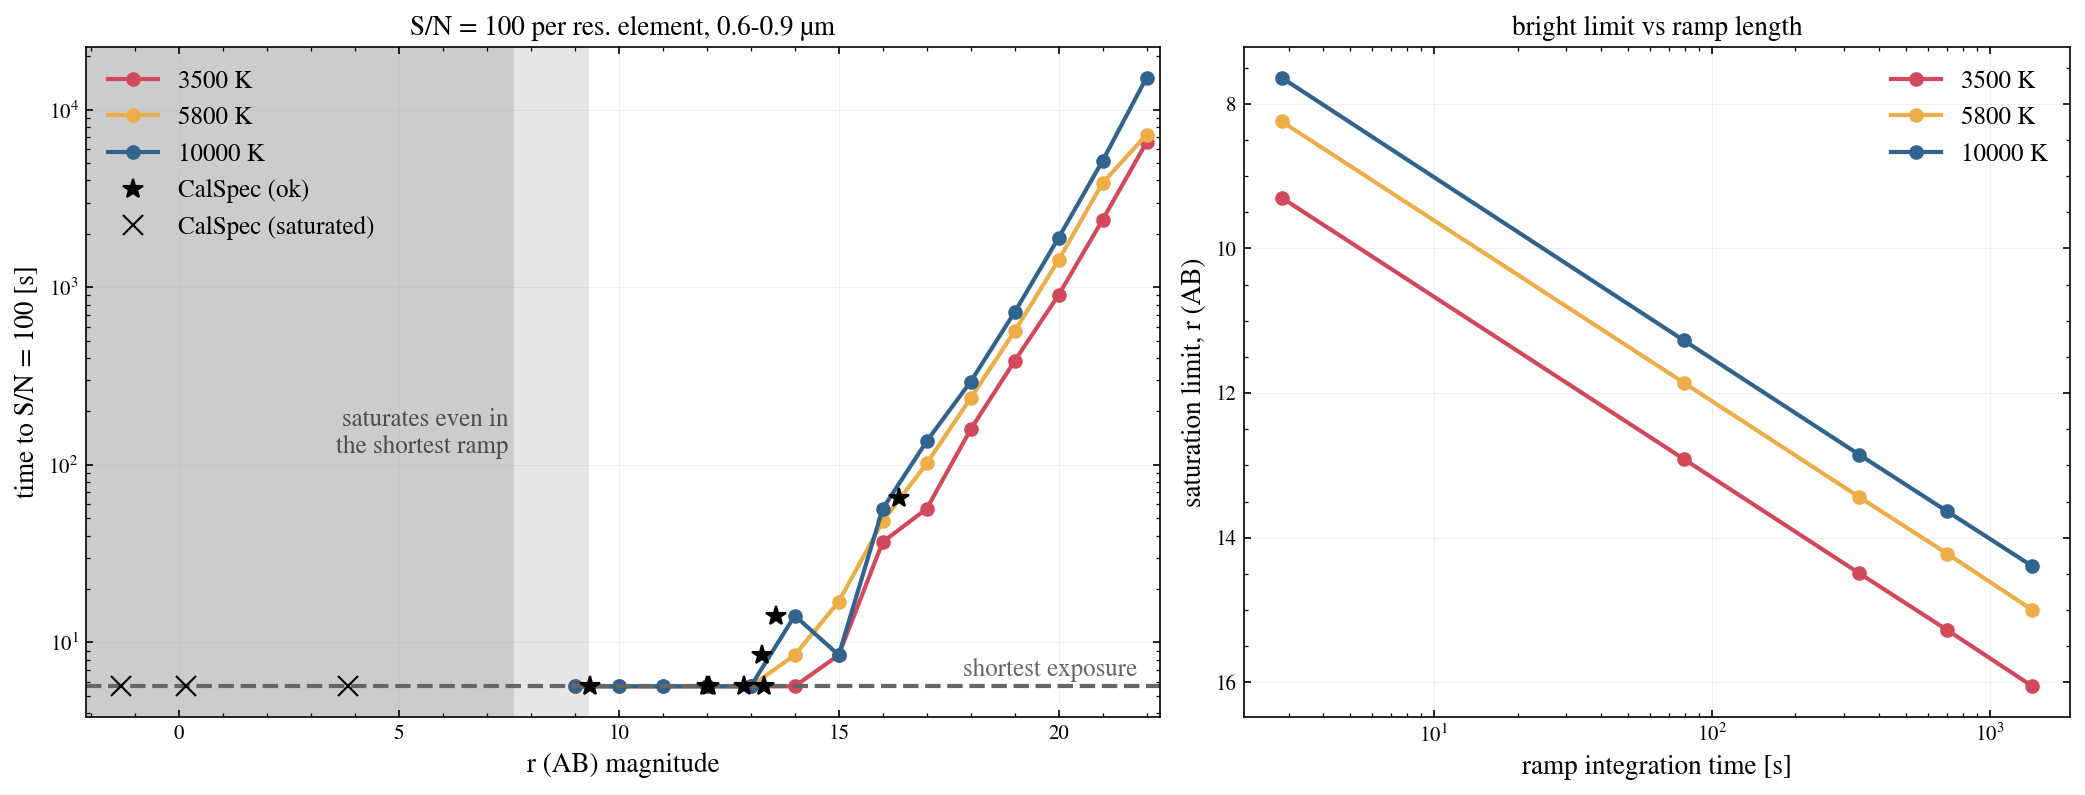

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw=dict(width_ratios=[1.3, 1]))
cols = {3500: '#d1495b', 5800: '#edae49', 10000: '#30638e'}
for T in TEMPS:
    ax1.semilogy(MAGS, T100[T], 'o-', color=cols[T], label=f'{T} K')
sat_lo = min(SAT[T, SHORTEST] for T in TEMPS); sat_hi = max(SAT[T, SHORTEST] for T in TEMPS)
xmin = min(r for _, r, *_ in rows) - 0.8
ax1.axvspan(xmin, sat_lo, color='0.8', zorder=0)
ax1.axvspan(sat_lo, sat_hi, color='0.9', zorder=0)
ax1.text(sat_lo - 0.15, 150, 'saturates even in\nthe shortest ramp', ha='right', va='center', fontsize=12, color='0.3')
ax1.axhline(bb.get_exposure_time(), color='0.4', ls='--')
ax1.text(21.8, 6.5, 'shortest exposure', ha='right', color='0.4', fontsize=12)
for name, r, sat, t, nmd in rows:
    ax1.plot(r, t, 'k*' if not sat else 'kx', ms=10, zorder=5)
ax1.plot([], [], 'k*', ms=10, label='CalSpec (ok)')
ax1.plot([], [], 'kx', ms=10, label='CalSpec (saturated)')
ax1.set(xlim=(xmin, MAGS[-1] + 0.3), xlabel='r (AB) magnitude', ylabel='time to S/N = 100 [s]',
        title='S/N = 100 per res. element, 0.6-0.9 µm')
ax1.legend(loc='upper left', fontsize=12)

for T in TEMPS:
    ax2.plot([tint[n] for n in MODES], [SAT[T, n] for n in MODES], 'o-', color=cols[T], label=f'{T} K')
ax2.set_xscale('log')
ax2.invert_yaxis()
ax2.set(xlabel='ramp integration time [s]', ylabel='saturation limit, r (AB)', title='bright limit vs ramp length')
ax2.legend(fontsize=12)
fig.tight_layout()
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

With the shortest MACC ramp (2 frames, 5.7 s), the IFS saturates at **r ≈ 7.6 (10 000 K), 8.2 (5800 K) and 9.3 (3500 K)**, and each factor of ~2 in ramp length moves the limit ~0.75 mag fainter. Down to r ≈ 13, S/N = 100 per resolution element (0.6–0.9 µm) is already reached in that minimum 5.7 s exposure. Of the CalSpec standards tested, Sirius, Vega and 109 Vir saturate; BD+17 4708, G191-B2B, Feige 110, P330E, GD 71, P177D and GD 153 all reach S/N 100 in ≤ 14 s, and C26202 (r = 16.4) in about a minute.

## Caveats & next steps

- **Saturation model:** slicersim flags saturation when the signal integrated over $(n-1)$ groups exceeds the detector `saturation` value (65535 ADU at gain 1). Real H4RG ramps also lose linearity before hard saturation, and the first read/reset frames are not modelled, so the true bright limit is probably a few tenths of a magnitude fainter. There is also no persistence model, which matters after observing bright standards.
- **Idealised point source:** perfect extraction, no pointing jitter or PSF-wing losses, no flat-field or calibration systematics; S/N = 100 here is photon/read-noise statistics only, which a real flux calibration will not reach without a systematic floor.
- **Read-out search is discrete:** `setup_to_snr` steps through MACC modes and is not perfectly monotonic (e.g. the 10 000 K star at r = 14 gets a longer mode than at r = 15), so read the curve as ±1 mode.
- **Shortest exposure is a hard floor** (the 2-frame ramp): the brightest usable stars are not faster to observe, just closer to saturation. Spacecraft overheads (slew, acquisition, dithering) are not included and will dominate for bright standards.
- **Ideas:** (1) repeat the S/N = 100 curve for the blue end (4000–5000 Å) where hot white dwarfs and cool stars differ most; (2) find the faintest CalSpec star that still reaches S/N = 100 in one full ramp; (3) use `get_variance_contribution()` to see where the read-noise-dominated regime ends.